In [1]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age",
    "sex",
    "chest_pain_type",
    "resting_blood_pressure",
    "cholesterol",
    "fasting_blood_sugar",
    "rest_ecg",
    "max_heart_rate_achieved",
    "exercise_induced_angina",
    "st_depression",
    "st_slope",
    "num_major_vessels",
    "thalassemia",
    "target"
]

heart = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?"
)

# Xóa các dòng có dữ liệu bị thiếu
heart.dropna(inplace=True)

# Chuyển dữ liệu sang kiểu số
heart = heart.apply(pd.to_numeric)

# Chuyển target thành 2 lớp: 0 và 1
heart["target"] = (heart["target"] > 0).astype(int)

print("Kích thước dữ liệu:", heart.shape)
print("\n5 dòng dữ liệu đầu tiên:")
display(heart.head())

print("\nThông tin dữ liệu:")
heart.info()

print("\nKiểm tra dữ liệu thiếu:")
print(heart.isnull().sum())

print("\nPhân bố thuộc tính target:")
print(heart["target"].value_counts())

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Kích thước dữ liệu: (297, 14)

5 dòng dữ liệu đầu tiên:


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
Index: 297 entries, 0 to 301
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      297 non-null    float64
 1   sex                      297 non-null    float64
 2   chest_pain_type          297 non-null    float64
 3   resting_blood_pressure   297 non-null    float64
 4   cholesterol              297 non-null    float64
 5   fasting_blood_sugar      297 non-null    float64
 6   rest_ecg                 297 non-null    float64
 7   max_heart_rate_achieved  297 non-null    float64
 8   exercise_induced_angina  297 non-null    float64
 9   st_depression            297 non-null    float64
 10  st_slope                 297 non-null    float64
 11  num_major_vessels        297 non-null    float64
 12  thalassemia              297 non-null    float64
 13  target                   297 non-null    int64  
dtypes: float64(

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008


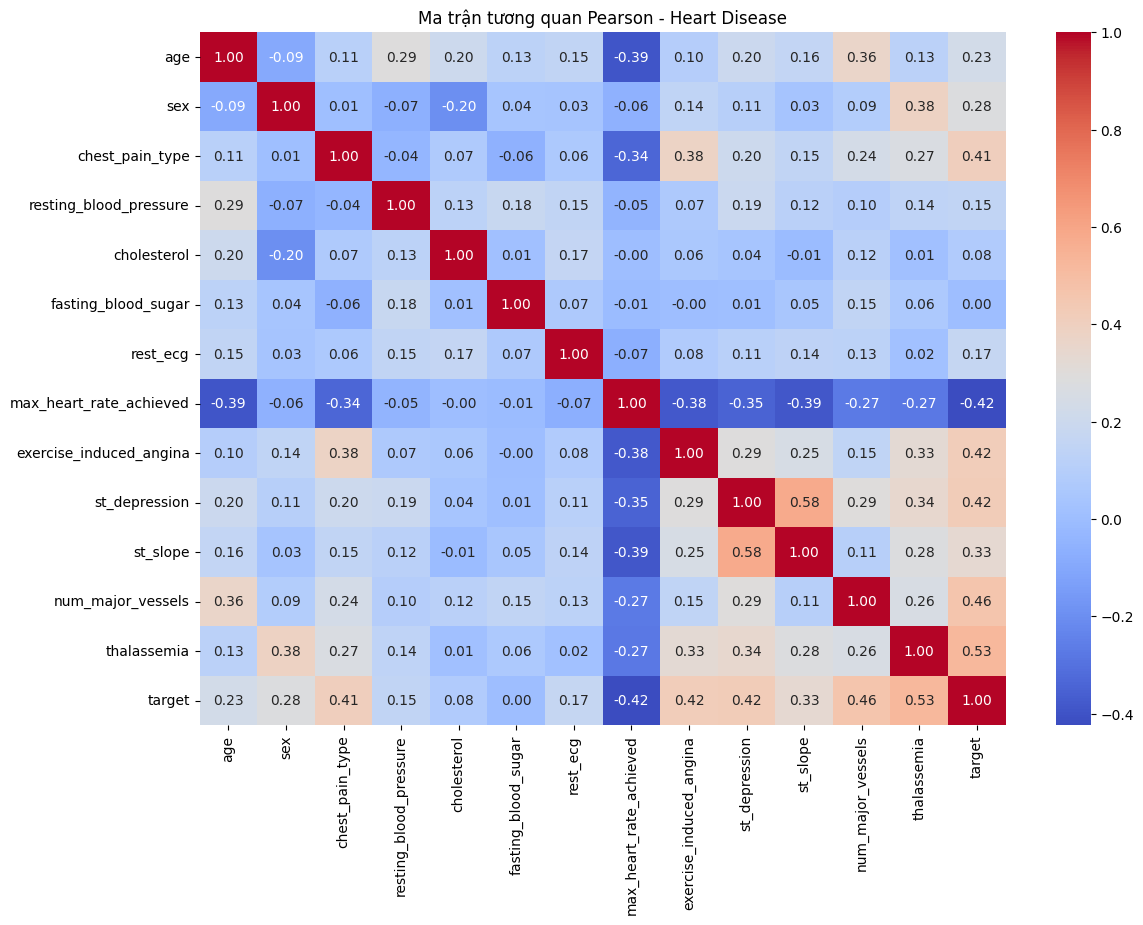

Các cột bị loại bỏ: []
Kích thước dữ liệu sau xử lý: (297, 14)


In [ ]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

corr = heart.corr(method="pearson")

plt.figure(figsize=(13, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Ma trận tương quan Pearson - Heart Disease")
plt.show()

columns_to_drop = set()

for i in range(len(corr.columns)):
    for j in range(i):
        if abs(corr.iloc[i, j]) > 0.9:
            col = corr.columns[i]
            if col != "target":
                columns_to_drop.add(col)

heart = heart.drop(columns=list(columns_to_drop))

print("Các cột bị loại bỏ:", list(columns_to_drop))
print("Kích thước dữ liệu sau xử lý:", heart.shape)

In [ ]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

features = heart.drop(columns=["target"])
labels = heart["target"]

print("Features:")
display(features.head())

print("Labels:")
display(labels.head())

print("Kích thước Features:", features.shape)
print("Kích thước Labels:", labels.shape)

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Features:


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0


Labels:


,target
0,0
1,1
2,1
3,0
4,0


Kích thước Features: (297, 13)
Kích thước Labels: (297,)


In [ ]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

features_encoded = pd.get_dummies(features)

print("Dữ liệu sau khi chuyển đổi One-hot:")
display(features_encoded.head())

print("Kích thước dữ liệu:", features_encoded.shape)

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Dữ liệu sau khi chuyển đổi One-hot:


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0


Kích thước dữ liệu: (297, 13)


In [ ]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

X_train, X_test, y_train, y_test = train_test_split(
    features_encoded,
    labels,
    test_size=0.3,
    random_state=42,
    stratify=labels
)

print("Số dòng huấn luyện:", len(X_train))
print("Số dòng kiểm thử:", len(X_test))
print("Tỷ lệ huấn luyện:", len(X_train) / len(heart))
print("Tỷ lệ kiểm thử:", len(X_test) / len(heart))

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Số dòng huấn luyện: 207
Số dòng kiểm thử: 90
Tỷ lệ huấn luyện: 0.696969696969697
Tỷ lệ kiểm thử: 0.30303030303030304


Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn ID3:
[[42  6]
 [17 25]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.71      0.88      0.79        48
           1       0.81      0.60      0.68        42

    accuracy                           0.74        90
   macro avg       0.76      0.74      0.73        90
weighted avg       0.76      0.74      0.74        90

Accuracy: 0.7444444444444445
Precision: 0.7560051029706579
Recall: 0.7444444444444445


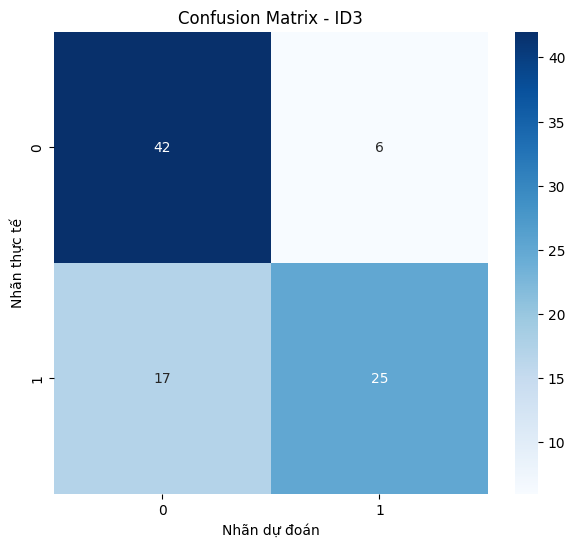

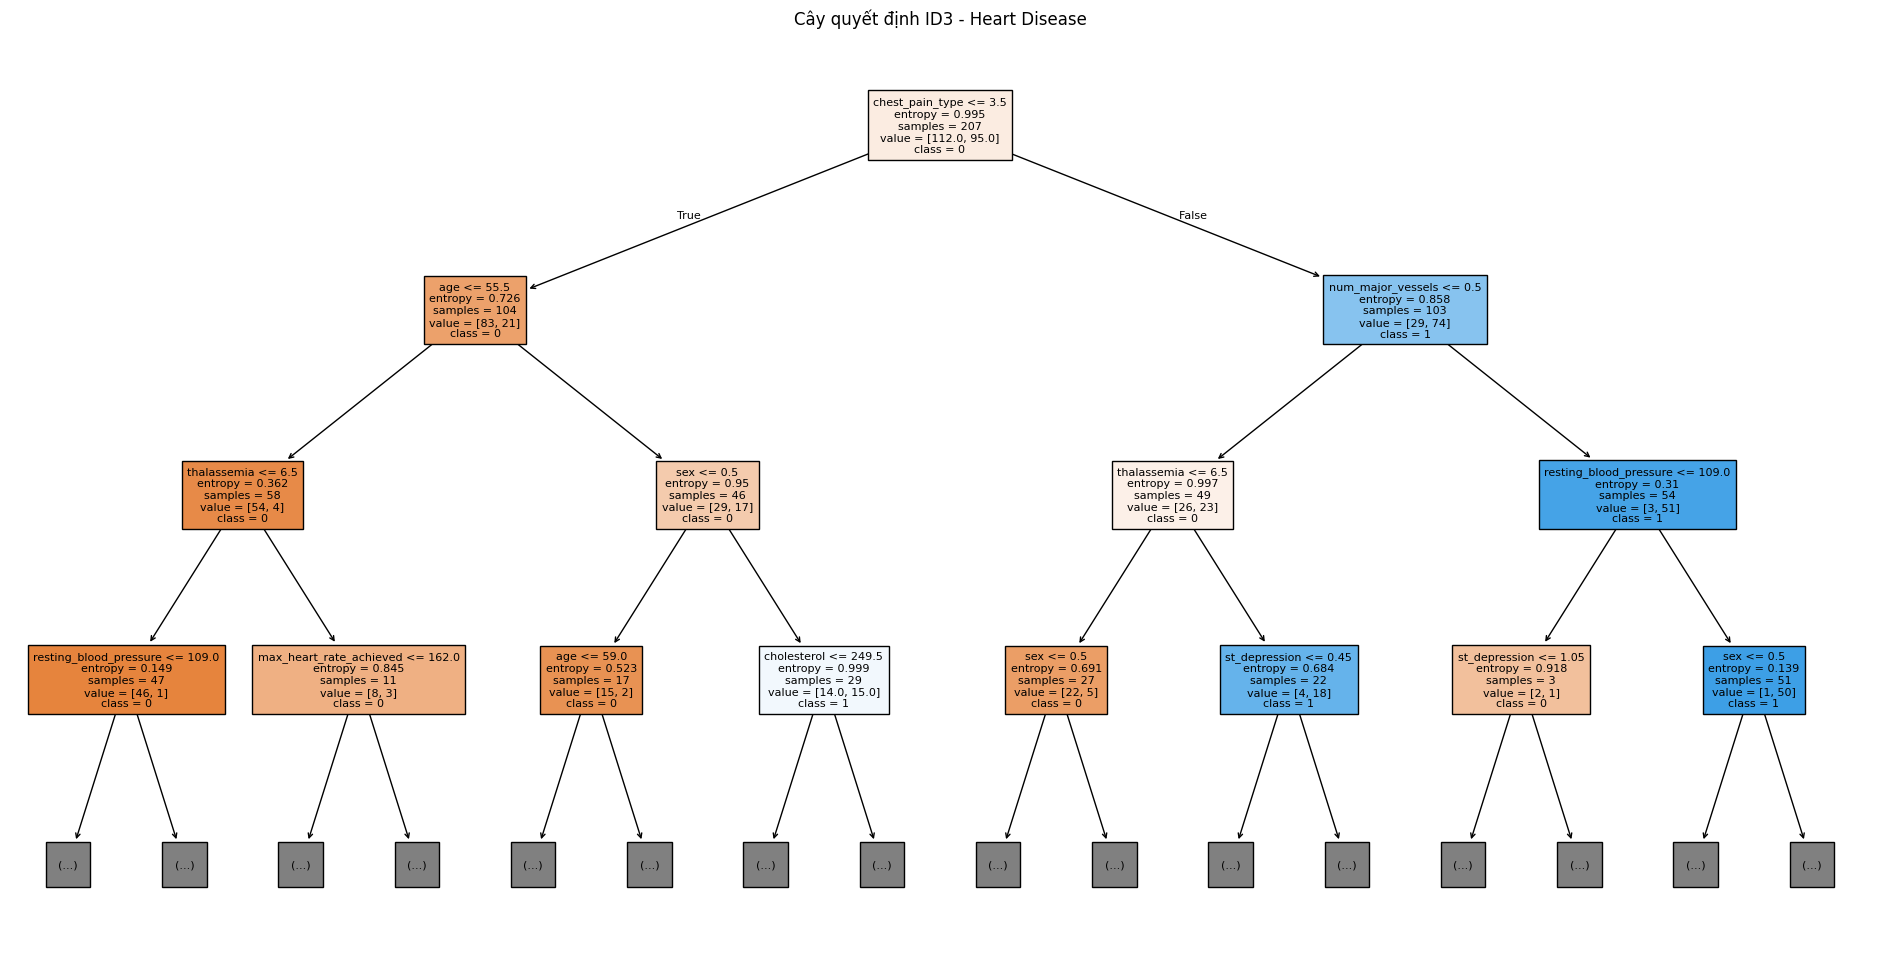

In [ ]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

id3_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

id3_model.fit(X_train, y_train)
y_pred_id3 = id3_model.predict(X_test)

cm_id3 = confusion_matrix(y_test, y_pred_id3)

print("Ma trận nhầm lẫn ID3:")
print(cm_id3)

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_id3, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred_id3))
print("Precision:", precision_score(
    y_test, y_pred_id3, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_id3, average="weighted", zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(cm_id3, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - ID3")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

plt.figure(figsize=(24, 12))
plot_tree(
    id3_model,
    feature_names=X_train.columns,
    class_names=[str(x) for x in id3_model.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Cây quyết định ID3 - Heart Disease")
plt.savefig("heart_ID3.png", dpi=100, bbox_inches="tight")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn CART:
[[40  8]
 [16 26]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.71      0.83      0.77        48
           1       0.76      0.62      0.68        42

    accuracy                           0.73        90
   macro avg       0.74      0.73      0.73        90
weighted avg       0.74      0.73      0.73        90

Accuracy: 0.7333333333333333
Precision: 0.7378151260504201
Recall: 0.7333333333333333


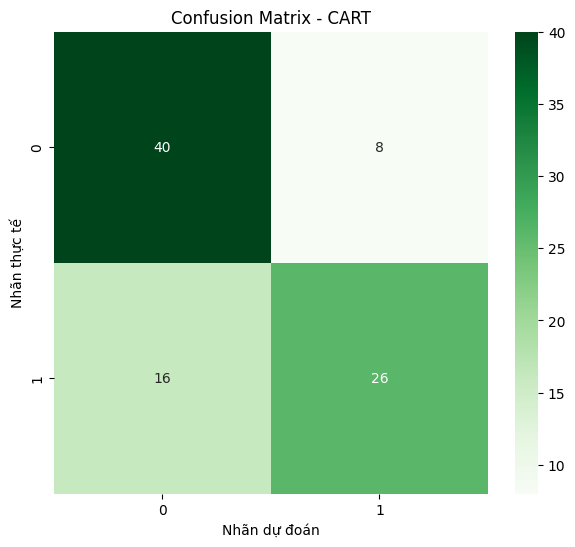

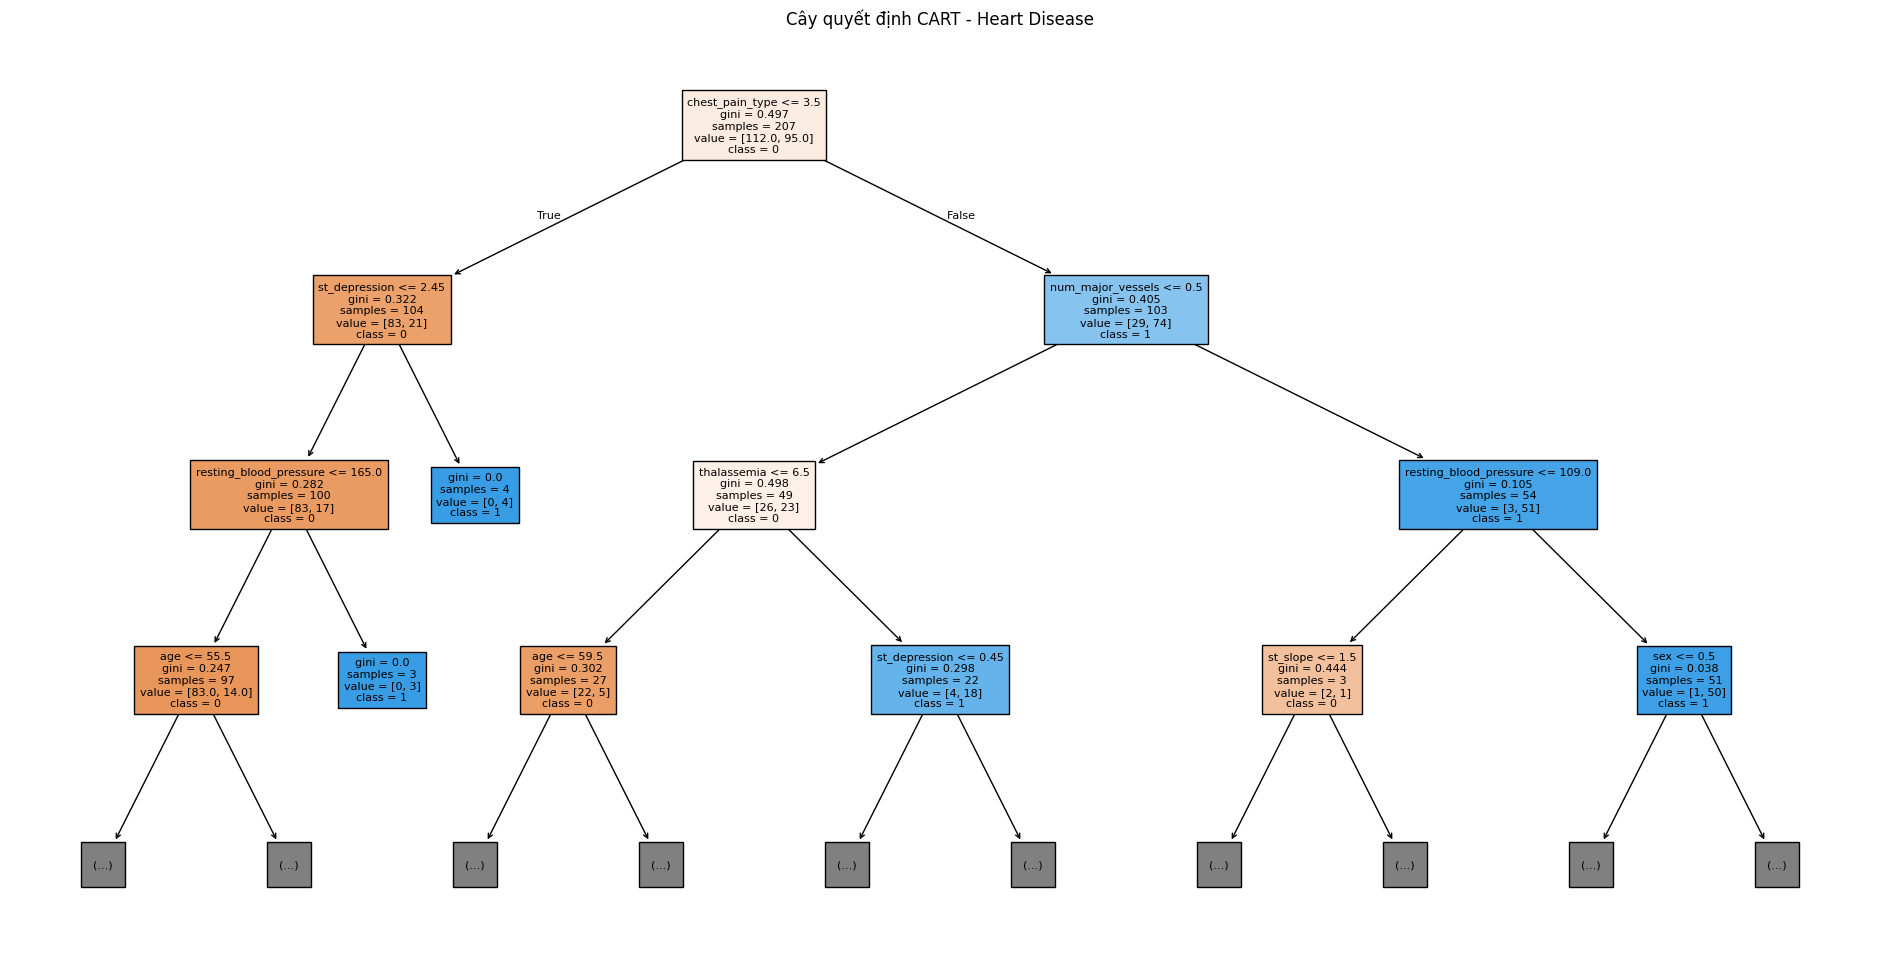

In [ ]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

cart_model.fit(X_train, y_train)
y_pred_cart = cart_model.predict(X_test)

cm_cart = confusion_matrix(y_test, y_pred_cart)

print("Ma trận nhầm lẫn CART:")
print(cm_cart)

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_cart, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred_cart))
print("Precision:", precision_score(
    y_test, y_pred_cart, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_cart, average="weighted", zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(cm_cart, annot=True, fmt="d", cmap="Greens")
plt.title("Confusion Matrix - CART")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

plt.figure(figsize=(24, 12))
plot_tree(
    cart_model,
    feature_names=X_train.columns,
    class_names=[str(x) for x in cart_model.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Cây quyết định CART - Heart Disease")
plt.savefig("heart_CART.png", dpi=100, bbox_inches="tight")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn Naïve Bayes:
[[43  5]
 [ 6 36]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.88      0.90      0.89        48
           1       0.88      0.86      0.87        42

    accuracy                           0.88        90
   macro avg       0.88      0.88      0.88        90
weighted avg       0.88      0.88      0.88        90

Accuracy: 0.8777777777777778
Precision: 0.8777833084453294
Recall: 0.8777777777777778


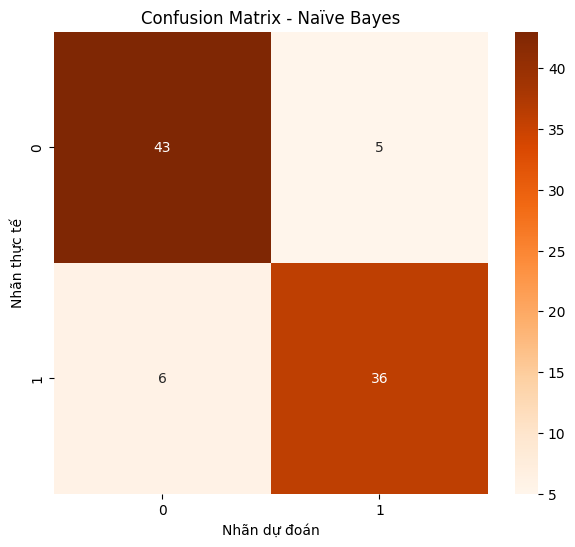

In [ ]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

cm_nb = confusion_matrix(y_test, y_pred_nb)

print("Ma trận nhầm lẫn Naïve Bayes:")
print(cm_nb)

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(
    y_test, y_pred_nb, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_nb, average="weighted", zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Oranges")
plt.title("Confusion Matrix - Naïve Bayes")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008


,Mô hình,Accuracy,Precision,Recall,F1-score
0,ID3,0.744444,0.756005,0.744444,0.738326
1,CART,0.733333,0.737815,0.733333,0.729555
2,Naïve Bayes,0.877778,0.877783,0.877778,0.877672


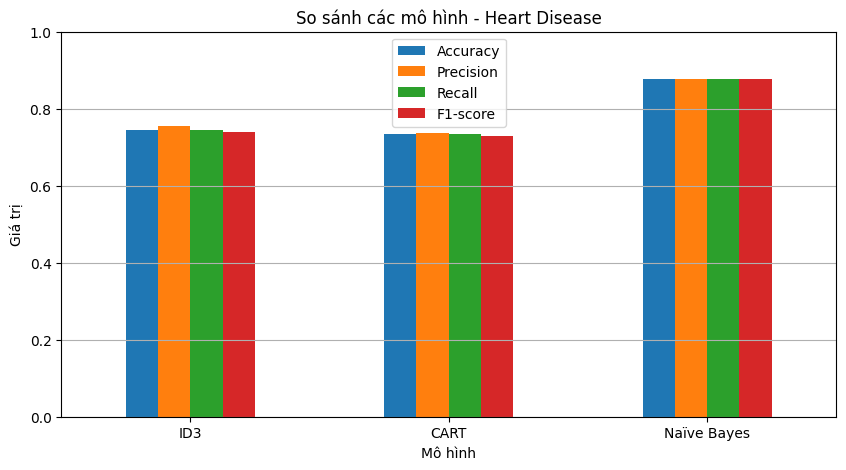

Mô hình có Accuracy cao nhất: Naïve Bayes


In [ ]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

results_heart = pd.DataFrame({
    "Mô hình": ["ID3", "CART", "Naïve Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_id3),
        accuracy_score(y_test, y_pred_cart),
        accuracy_score(y_test, y_pred_nb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ]
})

display(results_heart)

results_heart.set_index("Mô hình")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("So sánh các mô hình - Heart Disease")
plt.ylabel("Giá trị")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

print(
    "Mô hình có Accuracy cao nhất:",
    results_heart.loc[results_heart["Accuracy"].idxmax(), "Mô hình"]
)